# Tags 趨勢：供給、熱門、偏好（2016–2024）

- **供給**：當年開始連載的書裡，有這個 tag 的比例
- **熱門**：當年同季前 10% 的書裡，有這個 tag 的比例
- **偏好（lift）**：熱門比例 ÷ 供給比例。大於 1 表示這類書在熱門裡被放大
- 每一年的 Y 都是「同季前 10%」，只在同季內比，所以不同年份的 lift 可以互相比
- 注意：2023、2024 年的書被觀察的時間較短，「前 10%」比較接近「早期就衝起來」

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
OUT = Path("out"); FIG = OUT / "figs"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"font.sans-serif": ["PingFang TC", "Heiti TC", "Arial Unicode MS", "DejaVu Sans"], "axes.unicode_minus": False,
                     "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
S = {}
def save(name): plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
b = pd.read_parquet(OUT / "books_meta.parquet")
parse = lambda s: json.loads(s) if isinstance(s, str) and s else []
b["tags_l"] = b.tags.map(parse); b["warn_l"] = b.warnings.map(parse)
YEARS = list(range(2016, 2025))
print(len(b), b.year.value_counts().sort_index().to_dict())

45245 {2016: 2205, 2017: 2503, 2018: 2877, 2019: 2913, 2020: 4036, 2021: 4771, 2022: 5700, 2023: 8075, 2024: 12165}


## 1. 每年的供給、熱門與 lift

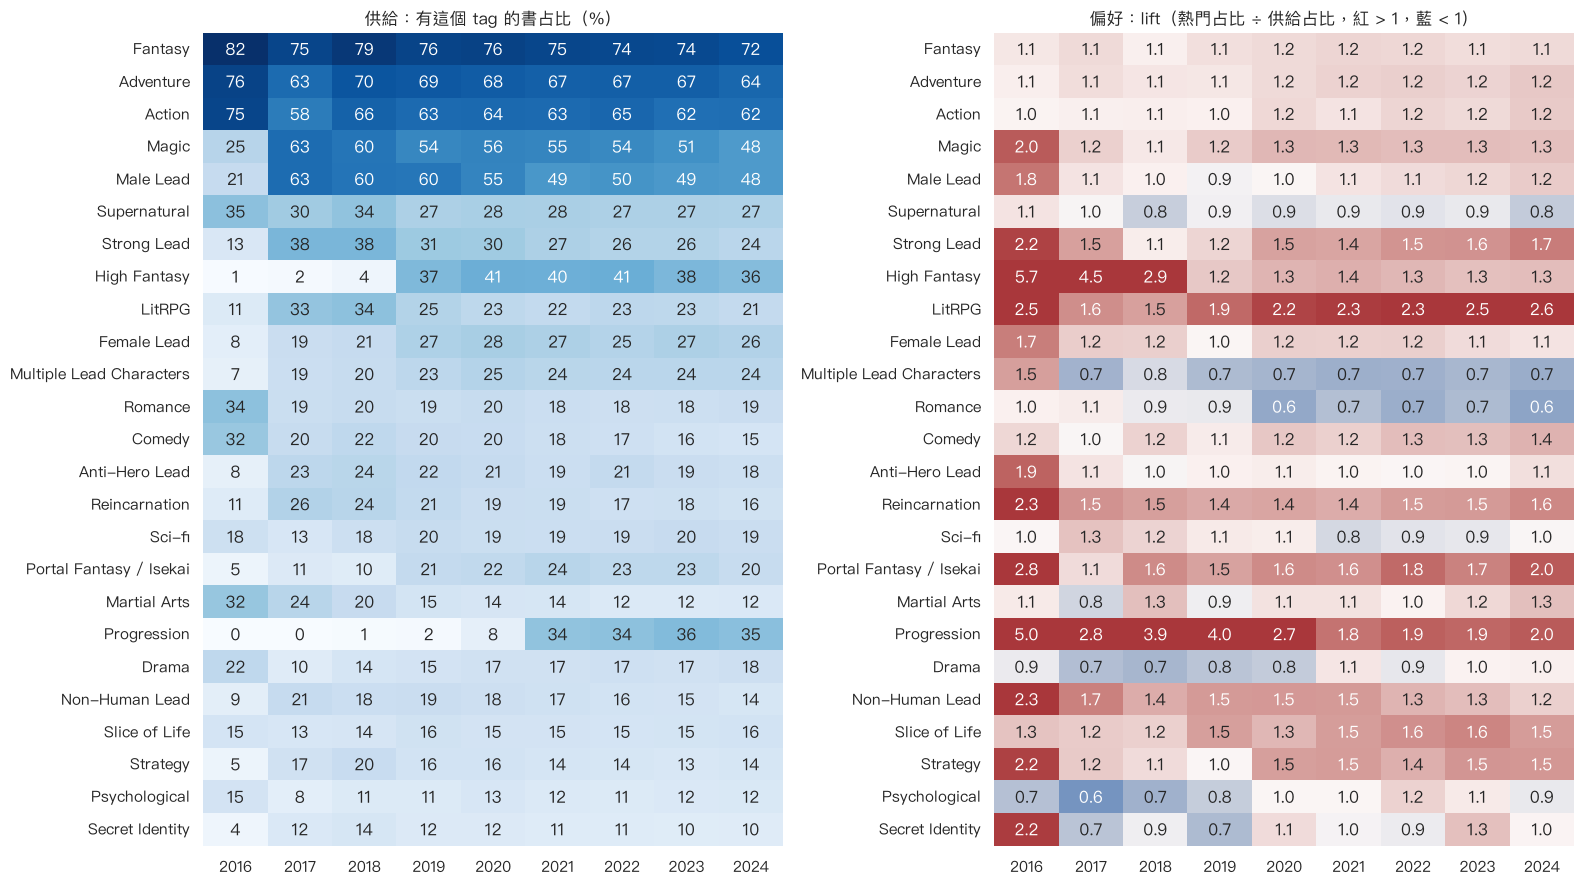

In [2]:
X = b[["fiction_id","year","top10","tags_l"]].explode("tags_l").dropna(subset=["tags_l"]).rename(columns={"tags_l":"tag"})
n_year = b.groupby("year").size(); n_top = b[b.top10].groupby("year").size()
sup = X.groupby(["tag","year"]).size().unstack().reindex(columns=YEARS).fillna(0).div(n_year, axis=1)
hot = X[X.top10].groupby(["tag","year"]).size().unstack().reindex(columns=YEARS).fillna(0).div(n_top, axis=1)
lift = hot / sup
common = sup.mean(axis=1).sort_values(ascending=False)
TOP = common.index[:25]
S["n_tags"] = int(sup.shape[0]); S["n_year"] = n_year.to_dict(); S["n_top"] = n_top.to_dict()
fig, ax = plt.subplots(1, 2, figsize=(16, 9))
sns.heatmap(sup.loc[TOP] * 100, ax=ax[0], cmap="Blues", annot=True, fmt=".0f", cbar=False); ax[0].set_title("供給：有這個 tag 的書占比（%）"); ax[0].set_xlabel(""); ax[0].set_ylabel("")
sns.heatmap(np.log2(lift.loc[TOP]), ax=ax[1], cmap="vlag", center=0, vmin=-1.2, vmax=1.2, annot=lift.loc[TOP].round(1), fmt="", cbar=False)
ax[1].set_title("偏好：lift（熱門占比 ÷ 供給占比，紅 > 1，藍 < 1）"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.tight_layout(); save("tags_supply_lift")

## 2. 供給變化最大的 tags

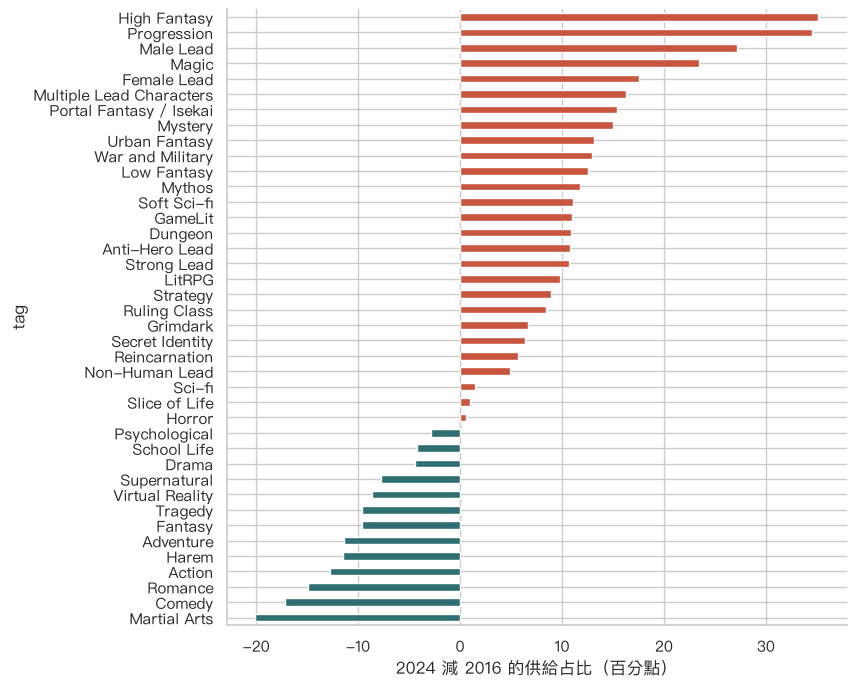

tag
Martial Arts               -20.1
Comedy                     -17.1
Romance                    -14.9
Action                     -12.8
Harem                      -11.5
Adventure                  -11.4
Multiple Lead Characters    16.3
Female Lead                 17.5
Magic                       23.5
Male Lead                   27.1
Progression                 34.6
High Fantasy                35.2
dtype: float64

In [3]:
chg = (sup[2024] - sup[2016]).loc[common.index[:40]].sort_values()
S["supply_change"] = (chg * 100).round(1).to_dict()
fig, ax = plt.subplots(figsize=(8, 8))
(chg * 100).plot.barh(ax=ax, color=np.where(chg > 0, "#c8553d", "#2f6f73")); ax.set_xlabel("2024 減 2016 的供給占比（百分點）")
save("tags_supply_change")
pd.concat([chg.head(6), chg.tail(6)]).mul(100).round(1)

## 3. 偏好穩不穩定：各年 lift 的相關

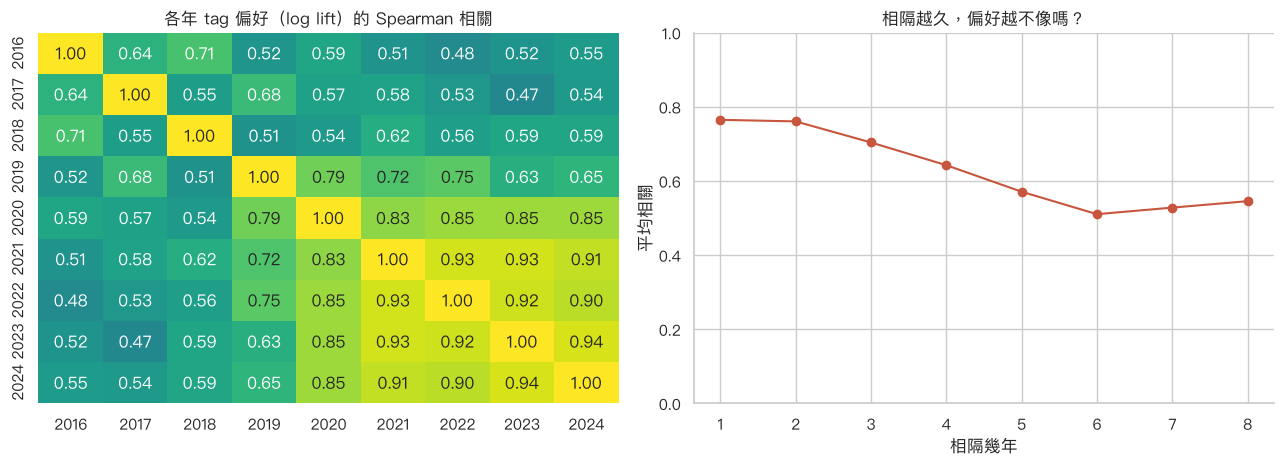

{'1': 0.765, '2': 0.761, '3': 0.704, '4': 0.642, '5': 0.571, '6': 0.51, '7': 0.528, '8': 0.545}


In [4]:
L = np.log2(lift.loc[common.index[:40]].clip(lower=1e-3))
corr = pd.DataFrame(index=YEARS, columns=YEARS, dtype=float)
for i in YEARS:
    for j in YEARS:
        corr.loc[i, j] = spearmanr(L[i], L[j])[0]
S["lift_corr"] = corr.round(3).to_dict()
gap = {d: float(np.mean([corr.loc[y, y + d] for y in YEARS if y + d in YEARS])) for d in range(1, 9)}
S["lift_corr_by_gap"] = {str(k): round(v, 3) for k, v in gap.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(corr.astype(float), ax=ax[0], cmap="viridis", annot=True, fmt=".2f", vmin=0, vmax=1, cbar=False); ax[0].set_title("各年 tag 偏好（log lift）的 Spearman 相關")
ax[1].plot(list(gap), list(gap.values()), marker="o", color="#c8553d"); ax[1].set_xlabel("相隔幾年"); ax[1].set_ylabel("平均相關"); ax[1].set_title("相隔越久，偏好越不像嗎？"); ax[1].set_ylim(0, 1)
plt.tight_layout(); save("tags_lift_stability")
print(S["lift_corr_by_gap"])

## 4. 幾個代表性 tags 的軌跡（含 bootstrap 95% 區間）

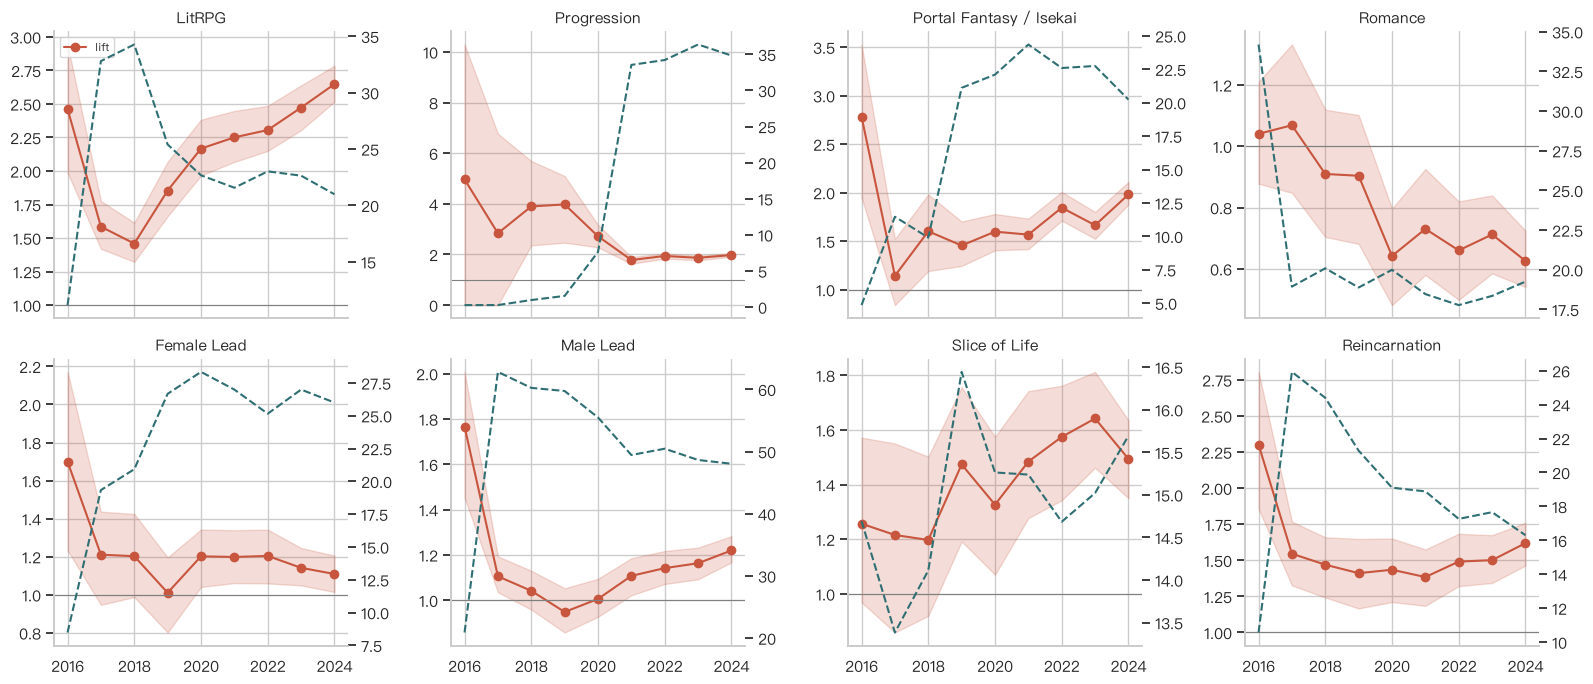

In [5]:
rng = np.random.default_rng(0)
PICK = [t for t in ["LitRPG", "Progression", "Portal Fantasy / Isekai", "Romance", "Female Lead", "Male Lead", "Slice of Life", "Reincarnation"] if t in sup.index]
def boot_lift(tag, year, B=300):
    d = b[b.year == year]; has = d.tags_l.map(lambda l: tag in l).values; top = d.top10.values; n = len(d)
    out = []
    for _ in range(B):
        idx = rng.integers(0, n, n); h, t = has[idx], top[idx]
        s = h.mean(); out.append((h & t).sum() / max(t.sum(), 1) / s if s > 0 else np.nan)
    return np.nanpercentile(out, [2.5, 97.5])
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
traj = {}
for ax, tag in zip(axes.ravel(), PICK):
    ci = np.array([boot_lift(tag, y) for y in YEARS])
    ax.fill_between(YEARS, ci[:, 0], ci[:, 1], color="#c8553d", alpha=.2); ax.plot(YEARS, lift.loc[tag, YEARS], color="#c8553d", marker="o", label="lift")
    ax2 = ax.twinx(); ax2.plot(YEARS, sup.loc[tag, YEARS] * 100, color="#2f6f73", ls="--", label="供給 %"); ax2.grid(False)
    ax.axhline(1, color="gray", lw=.8); ax.set_title(tag, fontsize=11)
    traj[tag] = {"lift": lift.loc[tag, YEARS].round(3).tolist(), "supply": (sup.loc[tag, YEARS] * 100).round(2).tolist(), "ci": ci.round(3).tolist()}
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); save("tags_trajectories")
S["trajectories"] = traj

## 5. 平台標籤本身的變化（避免假趨勢）

In [6]:
first_seen = (sup > 0.005).idxmax(axis=1).where((sup > 0.005).any(axis=1))
new_tags = first_seen[first_seen > 2016].sort_values()
S["tags_first_seen_after_2016"] = new_tags.astype(int).to_dict()
W = b[["year","top10","warn_l"]].explode("warn_l").dropna(subset=["warn_l"])
ws = W.groupby(["warn_l","year"]).size().unstack().reindex(columns=YEARS).fillna(0).div(n_year, axis=1)
S["warnings_supply"] = (ws * 100).round(2).to_dict("index")
print("2016 年以後才達到 0.5% 的 tags：", S["tags_first_seen_after_2016"]); (ws * 100).round(1)

2016 年以後才達到 0.5% 的 tags： {'Satire': 2017, 'GameLit': 2017, 'Progression': 2018, 'Urban Fantasy': 2018, 'Super Heroes': 2018, 'Ruling Class': 2018, 'Villainous Lead': 2018, 'Post Apocalyptic': 2018, 'Mythos': 2018, 'War and Military': 2018, 'Dungeon': 2018, 'Low Fantasy': 2018, 'Soft Sci-fi': 2019, 'Space Opera': 2019, 'Steampunk': 2019, 'Hard Sci-fi': 2020, 'Genetically Engineered': 2020, 'First Contact': 2020, 'Dystopia': 2020, 'Technologically Engineered': 2020, 'Time Loop': 2020, 'Time Travel': 2020, 'Attractive Lead': 2020, 'Artificial Intelligence': 2020}


year,2016,2017,2018,2019,2020,2021,2022,2023,2024
warn_l,,,,,,,,,
AI-Assisted Content,0.0,0.0,0.0,0.1,0.1,0.2,0.4,4.9,10.9
AI-Generated Content,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.8,2.2
Graphic Violence,20.1,53.8,50.0,49.3,46.9,47.8,48.1,53.2,59.0
Profanity,21.6,59.2,55.9,55.6,52.3,53.0,52.4,49.2,44.8
Sensitive Content,9.3,27.5,29.8,29.3,27.3,31.1,30.9,37.6,45.7
Sexual Content,34.5,10.3,17.4,26.4,22.3,22.3,19.0,17.1,15.0


## 6. 排除標籤系統的變化後，再看一次

2016 年每本書的 tag 中位數只有 6 個（之後 8 到 9 個），而且很多 tag（例如 Progression）是 2017 到 2020 年才開始被大量使用。
這比較像平台標籤清單或標記習慣改變，不是讀者口味改變。所以這裡排除 2016 年，並只保留 2017 年就已存在的 tags。

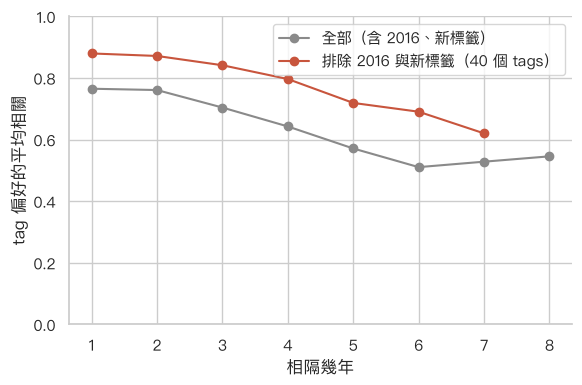

{'1': 0.879, '2': 0.871, '3': 0.841, '4': 0.796, '5': 0.719, '6': 0.69, '7': 0.62}


In [7]:
nt = b.tags_l.map(len); S["tags_per_book_med_by_year"] = nt.groupby(b.year).median().to_dict()
Y2 = YEARS[1:]
stable = [t for t in common.index[:60] if (sup.loc[t, 2017] > 0.005)][:40]
L2 = np.log2(lift.loc[stable, Y2].clip(lower=1e-3))
gap2 = {d: float(np.mean([spearmanr(L2[y], L2[y + d])[0] for y in Y2 if y + d in Y2])) for d in range(1, 8)}
S["lift_corr_by_gap_clean"] = {str(k): round(v, 3) for k, v in gap2.items()}; S["n_stable_tags"] = len(stable)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(list(gap), list(gap.values()), marker="o", color="#8a8a8a", label="全部（含 2016、新標籤）")
ax.plot(list(gap2), list(gap2.values()), marker="o", color="#c8553d", label=f"排除 2016 與新標籤（{len(stable)} 個 tags）")
ax.set_xlabel("相隔幾年"); ax.set_ylabel("tag 偏好的平均相關"); ax.set_ylim(0, 1); ax.legend()
save("tags_lift_stability_clean")
print(S["lift_corr_by_gap_clean"])

In [8]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    return o
(OUT / "tags_summary.json").write_text(json.dumps(clean(S), ensure_ascii=False, indent=1)); print("saved")

saved
